In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import  LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LassoCV


from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

In [13]:
data=pd.read_csv("/content/CarPrice_Assignment.csv")

In [14]:
data.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [15]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [16]:
data.drop(["car_ID","CarName"], axis="columns",inplace = True)

In [20]:
data.select_dtypes(include=["object"]).columns

Index(['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel',
       'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem'],
      dtype='object')

In [21]:
encoders={}
for col in data.select_dtypes(include=["object"]).columns:
  le = LabelEncoder()
  data[col]=le.fit_transform(data[col])
  encoders[col] = le

In [22]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   symboling         205 non-null    int64  
 1   fueltype          205 non-null    int64  
 2   aspiration        205 non-null    int64  
 3   doornumber        205 non-null    int64  
 4   carbody           205 non-null    int64  
 5   drivewheel        205 non-null    int64  
 6   enginelocation    205 non-null    int64  
 7   wheelbase         205 non-null    float64
 8   carlength         205 non-null    float64
 9   carwidth          205 non-null    float64
 10  carheight         205 non-null    float64
 11  curbweight        205 non-null    int64  
 12  enginetype        205 non-null    int64  
 13  cylindernumber    205 non-null    int64  
 14  enginesize        205 non-null    int64  
 15  fuelsystem        205 non-null    int64  
 16  boreratio         205 non-null    float64
 1

In [27]:
corr_with_price = data.corrwith(data['price']).sort_values()

In [30]:
corr_data=corr_with_price.reset_index()
corr_data.columns=["Параметр","Корреляция"]

In [31]:
corr_data

,Параметр,Корреляция
0,highwaympg,-0.697599
1,citympg,-0.685751
2,fueltype,-0.105679
3,peakrpm,-0.085267
4,carbody,-0.083976
5,symboling,-0.079978
6,doornumber,-0.031835
7,cylindernumber,-0.027628
8,enginetype,0.049171
9,compressionratio,0.067984


In [32]:
dataForGraph = corr_data['Корреляция'].values.reshape(-1,1)

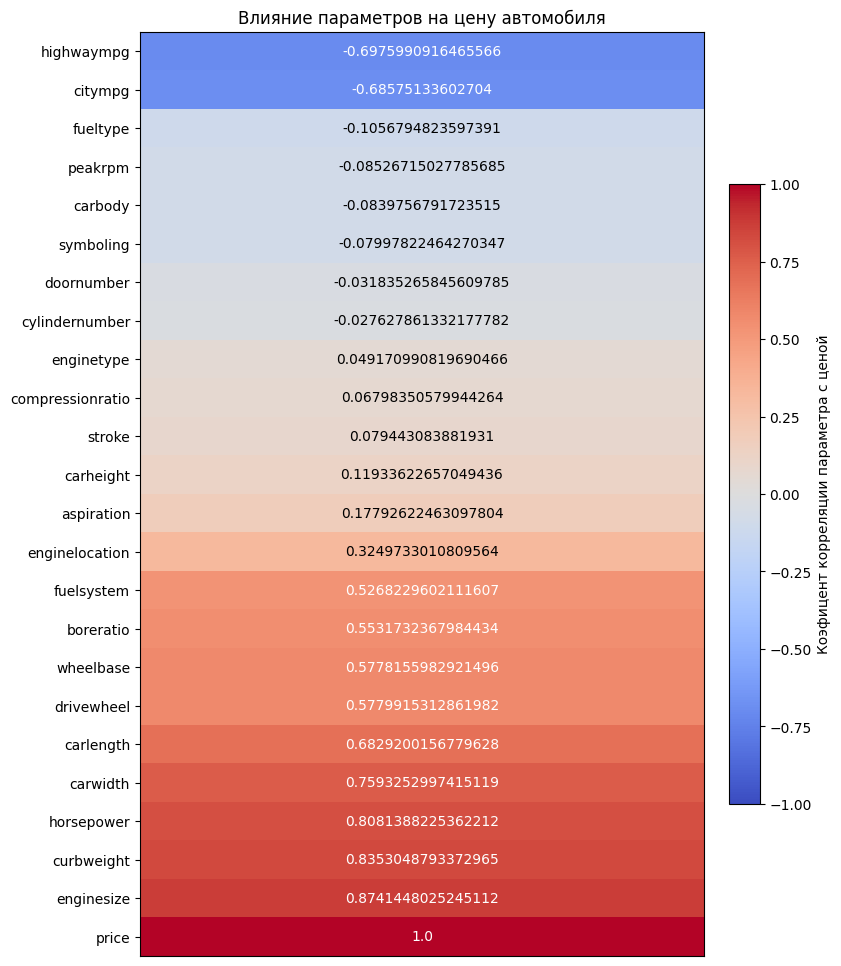

In [41]:
features_num=len(corr_data)
fig,ax = plt.subplots(figsize=(8,features_num * 0.5))

im = ax.imshow(dataForGraph,cmap="coolwarm",vmin=-1,vmax=1,aspect="auto")
ax.set_yticks(np.arange(features_num))
ax.set_yticklabels(corr_data["Параметр"])
ax.set_xticks([])

for i in range (features_num):
  val = dataForGraph[i,0]
  if abs(val) >0.4:
    text_color ="white"
  else:
    text_color="black"

  ax.text(0,i,val,ha="center",va="center",color=text_color)

cbar = plt.colorbar(im,ax=ax,fraction=0.05,pad=0.04)
cbar.set_label("Коэфицент корреляции параметра с ценой")

plt.title("Влияние параметров на цену автомобиля")
plt.show()


In [43]:
X =data.drop(["price"],axis=1)
Y =data["price"]
X_train,X_test,Y_train,Y_test= train_test_split(X,Y,test_size=0.2,random_state=44)

In [48]:
reg=LinearRegression()
reg.fit(X_train,Y_train)
pred=reg.predict(X_test)
print(pred)
print(mean_absolute_percentage_error(Y_test,pred))
print(mean_squared_error(Y_test,pred)**0.5)

[25230.20280317  7500.05494073  7525.97723009 11230.63176507
  8282.78781572 19171.01263603 10648.27754227  9749.712266
  9545.78225897 10480.49880131 15257.42103497  6157.48159739
  9410.10786682 20966.52423032 16949.49534374  7857.12212828
  9265.68553691 10287.23517586 11642.83588629 29757.02714275
  8991.4503893  34381.99534015  8671.78099711 18642.19964457
 14185.50452819  5488.90885613 16817.53142473 11889.87955256
 11191.23895782 20826.59748323  8005.90480337  6815.60339592
  8785.25457306 18879.50060659 20908.66569377 41092.59102176
 15316.25164646 16873.5022836   6342.76786566 10058.91087829
  6656.29197983]
0.1647504791244121
3053.26454675412


In [50]:
forrest=RandomForestRegressor()
forrest.fit(X_train,Y_train)
pred=forrest.predict(X_test)
print(pred)
print(mean_absolute_percentage_error(Y_test,pred))
print(mean_squared_error(Y_test,pred)**0.5)

[17266.01        8408.47        7641.16        9845.38333333
  8207.6        16111.94        9832.31       10707.15
  8306.83333333 12959.945      14971.3475      7292.72
  9126.30333333 18206.04       17266.57        8088.54
  7354.185      13458.03       10836.10666667 33741.65
  7936.12       32304.375      10354.95       19642.68
 18923.69        5963.8        15289.625       9537.4
  9380.75       18206.04        8226.85        7612.225
  9657.41       17610.69       14736.95       39648.01
 14624.185      13917.4575      5734.155      11189.97666667
  6436.94      ]
0.105808925974893
1950.498016111404


In [52]:
lasso=LassoCV()
lasso.fit(X_train,Y_train)
pred=lasso.predict(X_test)
print(pred)
print(mean_absolute_percentage_error(Y_test,pred))
print(mean_squared_error(Y_test,pred)**0.5)

[23535.17555757  6608.61856099  6702.88348888 12169.64920034
  8626.28424579 15478.86850294 11686.75707839 10984.37392876
  9810.2610887  10819.75951452 15691.13950315  6788.71591714
  7067.30808083 19219.54339647 18373.12774667  7267.29864468
  8059.48233885 13167.02271938 12269.19314148 35344.66372552
  7864.50491955 23989.57110463  9977.77089082 17537.36035067
 16048.50665925  4418.71722113 18300.37355337 10981.33385739
 10296.93170313 18872.98316912  8733.40286151  6350.27366424
  9303.45100604 17374.72100716 23866.64213094 38590.39313075
 15162.55163389 17952.13638926  6079.90096335  8705.59279194
  6433.03140156]
0.17870953235390866
3265.0630605258634
